# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [3]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata["champion"])
print("Test:", X_test.shape)

Modelo: logistic_regression
Test: (36, 13)


## 2. Evaluación final

Accuracy en test: 0.9722
F1 macro en test: 0.9710
Accuracy en validación cruzada (training_metadata): 0.9791

              precision    recall  f1-score   support

     clase 0       1.00      1.00      1.00        12
     clase 1       0.93      1.00      0.97        14
     clase 2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



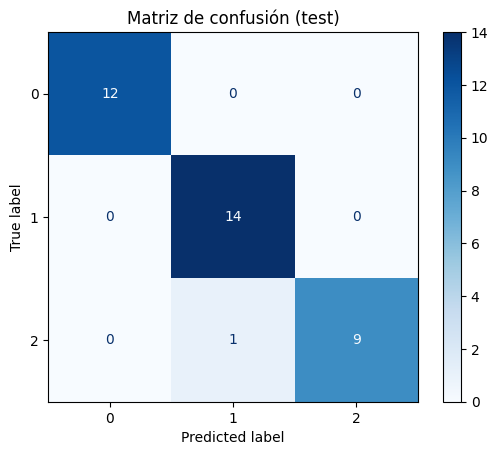

Errores: 1 de 36


,real,predicho
1,2,1


In [4]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy en test: {accuracy:.4f}")
print(f"F1 macro en test: {f1_macro:.4f}")
print(f"Accuracy en validación cruzada (training_metadata): {training_metadata['cv_score']:.4f}")
print()
print(classification_report(y_test, y_pred, target_names=[f"clase {c}" for c in sorted(y_test.unique())]))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Matriz de confusión (test)")
plt.show()

# Pares de clases confundidas (real -> predicho)
errors = pd.DataFrame({"real": y_test, "predicho": y_pred})
errors = errors[errors["real"] != errors["predicho"]]
print("Errores:", len(errors), "de", len(y_test))
errors

**Análisis:**

> - **Coherencia con la validación cruzada:** sí. El accuracy en test (0.972, es decir 35 de 36 aciertos) es muy cercano al de CV (0.979), y el F1 macro es 0.971. La diferencia de ~0.007 equivale a menos de una muestra, así que está dentro del ruido esperado.
> - **Clases confundidas:** hubo un único error, una muestra de la **clase 2** clasificada como **clase 1**. Por eso la clase 2 tiene recall 0.90 y la clase 1 precision 0.93. La clase 0 se clasificó sin errores.
> - **Sobreajuste:** no hay evidencia. El rendimiento en datos que el modelo nunca vio es prácticamente igual al de validación cruzada, y la brecha train–validación ya era pequeña (~0.02).
> - **Cautela:** el conjunto de test tiene solo 36 muestras (10 en la clase 2), así que cada error mueve el accuracy casi 3 puntos. Los resultados son alentadores, pero no hay que sobreinterpretarlos.

## 3. Función de inferencia

In [5]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve las predicciones del pipeline."""
    if not isinstance(records, pd.DataFrame):
        raise TypeError("records debe ser un pandas.DataFrame")

    # Verifica columnas faltantes
    missing = [c for c in feature_columns if c not in records.columns]
    if missing:
        raise ValueError(f"Faltan columnas requeridas: {missing}")

    # Ordena las columnas como feature_columns (ignora columnas extra, p. ej. target)
    X = records[feature_columns]

    # Devuelve prediction y probabilidades
    result = pd.DataFrame({"prediction": model.predict(X)}, index=records.index)
    probabilities = model.predict_proba(X)
    for i, cls in enumerate(model.classes_):
        result[f"proba_class_{cls}"] = probabilities[:, i].round(4)
    return result

## 4. Predicción por lotes

In [6]:
# Simulación de datos nuevos. En producción no provendrían del test set.
new_records = X_test.iloc[:5].copy()

batch_predictions = predict(new_records)
batch_predictions.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)
print("Predicciones guardadas en", REPORTS_DIR / "batch_predictions.csv")
display(batch_predictions)

# Prueba de la validación de esquema: debe fallar con un mensaje claro
try:
    predict(new_records.drop(columns=["alcohol"]))
except ValueError as e:
    print("Validación OK ->", e)

# Las columnas en otro orden no deben afectar el resultado
shuffled = new_records[new_records.columns[::-1]]
assert predict(shuffled)["prediction"].tolist() == batch_predictions["prediction"].tolist()
print("El orden de las columnas no afecta la predicción.")

Predicciones guardadas en /home/claude/work6/reports/batch_predictions.csv


,prediction,proba_class_0,proba_class_1,proba_class_2
0,0,0.9997,0.0003,0.0000
1,1,0.0071,0.5404,0.4525
2,0,0.9920,0.0077,0.0003
3,1,0.2900,0.7075,0.0026
4,1,0.0330,0.9623,0.0047


Validación OK -> Faltan columnas requeridas: ['alcohol']
El orden de las columnas no afecta la predicción.


## 5. Reporte final

In [7]:
test_metrics = {
    "model": training_metadata["champion"],
    "accuracy": float(accuracy),
    "f1_macro": float(f1_macro),
}
(REPORTS_DIR / "test_metrics.json").write_text(
    json.dumps(test_metrics, indent=2), encoding="utf-8"
)
print(json.dumps(test_metrics, indent=2))

{
  "model": "logistic_regression",
  "accuracy": 0.9722222222222222,
  "f1_macro": 0.9709618874773139
}


In [8]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón | Regresión logística (`C=1`) con `StandardScaler` en el pipeline |
| Accuracy CV | 0.979 (5 folds estratificados) |
| Accuracy test | 0.972 (35/36) |
| F1 macro test | 0.971 |
| Clases más confundidas | Clase 2 predicha como clase 1 (1 caso) |
| Principal limitación | Test de solo 36 muestras: la estimación es poco precisa (un error cambia ~3 puntos). El dataset es pequeño y de un solo origen, y no se probó con datos de otras cosechas o regiones |

## Checklist

- [x] Evalué únicamente el modelo campeón.
- [x] No reajusté hiperparámetros después de observar test.
- [x] Implementé validación básica del esquema de entrada.
- [x] Generé predicciones por lotes.
- [x] Guardé las métricas finales.